<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [VGI Hydrology Worker](https://github.com/Query-farm/vgi-hydrology)

Upstream catchments and land-cover summaries for monitoring stations.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-hydrology/blob/main/notebooks/02_pages_are_not_procurement_completeness.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-hydrology/blob/main/notebooks/README.md)


## 02 · A complete page stream can still leave a plan incomplete

Can a fully retrieved inventory price every requested line in a synthetic equipment
plan? We generate eight expected IDs, fetch a seven-item paginated catalog, and retain
missing items, missing prices and missing display labels through a left join. A known
subtotal is useful evidence, but it is not a complete quote.

This notebook exercises the released worker's **`examples` starter schema**, separate
from its GIS catchment analysis. The HTTP service is a deterministic local fixture
bound to `127.0.0.1`; all rows, prices and contacts are synthetic. No supplier, order,
email, real credential or external data service is contacted. Greetings are output
strings only.

### Change the page size, keep the catalog and plan fixed

`PAGE_SIZE` is **3** by default; the experiment uses **1**. It changes HTTP page
boundaries, not the seven fixture rows, their order, the eight requested IDs or quantities.
The fixture intentionally omits ID 8, leaves ID 5's price missing, and leaves ID 6's
item name missing. These represent distinct information gaps, not zero prices.

The helper accepts only the public fake token shown below and implements read-only
GET pages. Its audit stores page number, page size and status, never credentials.

In [1]:
PAGE_SIZE = 3  # Experiment: 1; valid integer range 1–7.

### Run this notebook

Read the saved outputs on GitHub or use **Open in Colab**, then Run All. The base shared
package preserves compatible preloaded plotting/data libraries. Initial packages,
companions, extension and released Git worker need internet; analytical inputs are
synthetic and local. The worker's separate environment supplies its declared Python
and GIS dependencies. PyFlwDir's first JIT compilation can take longer than later runs.

No local source checkout or real API credentials are required. Actual hosted Colab is
not claimed; a fresh preloaded Python 3.12 notebook-only execution tests the same
installation, verified-companion and released-launch path.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.26":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.26"
if "rasterio" not in installed:
    %pip install -q "rasterio>=1.4,<2"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.26":
    raise RuntimeError("Install shared tools v0.3.26, then restart and run all.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from vgi_notebooks.bootstrap import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("hydrology")
%matplotlib inline
theme()
session = connect(globals())
con = session.connection

from inventory_fixture import InventoryFixture

if type(PAGE_SIZE) is not int or not 1 <= PAGE_SIZE <= 7:
    raise ValueError("PAGE_SIZE must be an integer from 1 through 7")
fixture = InventoryFixture()
inventory_base_url = fixture.base_url
plan = summary = pages = pd.DataFrame()

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'hydrology' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-hydrology@v0.1.0 vgi-hydrology-worker');

,Success


### Use only a temporary fixture credential

The shared connection already verified an empty temporary SQL-secret directory before
ATTACH, with persistent secrets disabled. Create one **TEMPORARY** secret containing
this intentionally public fake value. It overrides no user's saved credential and is
accepted only by the local fixture. The notebook never reads environment credentials.
Cleanup drops this secret, closes the SQL session and stops the fixture server.

In [5]:
%%sql
CREATE TEMPORARY SECRET notebook_inventory (TYPE hydrology_api,
 TOKEN 'synthetic-hydrology-notebook-only');
SELECT name,type,persistent,storage FROM duckdb_secrets();

,name,type,persistent,storage
0,notebook_inventory,hydrology_api,False,memory


In [6]:
inventory = con.execute("SELECT name,type,persistent FROM duckdb_secrets()").fetchall()
assert inventory == [("notebook_inventory", "hydrology_api", False)]
assert inventory_base_url.startswith("http://127.0.0.1:")

### Generate the expected keys before retrieving actual rows

`sequence_table(8)` creates n=0 through 7. SQL turns these into requested item IDs
1–8 and quantities cycling 1, 2, 3. The squared output is checked against n×n;
it is an SDK demonstration field, not a financial quantity. An independent plan
prevents the fetched rows from defining their own completeness denominator.

`fetch_items` follows `next_page` until exhausted. We materialize its result once,
then display local tables: capturing a worker SELECT directly could repeat HTTP work.
A successful page stream proves retrieval from this fixture, not that the source
catalog contains everything in the plan.

In [7]:
%%sql
CREATE TABLE generated AS SELECT * FROM hydrology.examples.sequence_table(8);
CREATE TABLE requested AS SELECT n+1 AS item_id,1+n%3 AS quantity FROM generated;
CREATE TABLE catalog AS SELECT * FROM hydrology.examples.fetch_items(
 '{{inventory_base_url}}',page_size := {{PAGE_SIZE}});
CREATE TABLE contacts AS SELECT * FROM (VALUES
 ('hardware','Ada'),('software','Lin'),('service',NULL)
) AS c(category,contact_name);
SELECT * FROM catalog ORDER BY id;

,id,name,category,price
0,1,Gauge,hardware,120.0
1,2,Cable,hardware,15.0
2,3,Mapping license,software,60.0
3,4,Mount,hardware,25.0
4,5,Battery,hardware,NaN
5,6,None,service,45.0
6,7,Logger,hardware,85.0


In [8]:
pages = pd.DataFrame(fixture.requests)
assert len(pages) == (7 + PAGE_SIZE - 1) // PAGE_SIZE
assert pages.status.eq(200).all() and pages.page.tolist() == list(range(1, len(pages) + 1))
assert pages.page_size.eq(PAGE_SIZE).all()
display(pages)
prose(
    f"The real released REST reader made **{len(pages)} successful local GET requests**, "
    f"with page size **{PAGE_SIZE}**, and returned seven catalog rows. No retries or writes were needed. "
    "The expected plan still has eight lines; the source is deliberately incomplete for that plan."
)

,page,page_size,status
0,1,3,200
1,2,3,200
2,3,3,200


The real released REST reader made **3 successful local GET requests**, with page size **3**, and returned seven catalog rows. No retries or writes were needed. The expected plan still has eight lines; the source is deliberately incomplete for that plan.

### Keep absent rows, absent prices and absent labels distinct

A left join retains all eight requested IDs. `fetch_items` returns a floating-point
price; the fixture values are exact whole-dollar amounts, and SQL converts them to
`DECIMAL(12,2)` before quantity multiplication. General financial inputs need an
appropriate decimal-source contract; this conversion cannot recover precision already
lost upstream.

The `greet` scalar produces casual and formal contact labels, using its two overloads.
A missing contact stays NULL. Labels do not identify, authenticate or message a person;
we preserve missing labels beside the plan instead of filtering away those rows.
An available price can coexist with a missing display name or contact.

In [9]:
%%sql
CREATE TABLE plan AS
SELECT r.item_id,r.quantity,c.name AS item_name,c.category,c.price::DECIMAL(12,2) AS unit_price_usd,
 c.price::DECIMAL(12,2)*r.quantity AS known_line_usd,
 CASE WHEN c.id IS NULL THEN 'Missing item' WHEN c.price IS NULL THEN 'Missing price' ELSE 'Priced' END AS price_status,
 p.contact_name,hydrology.examples.greet(p.contact_name) AS casual_label,
 hydrology.examples.greet(p.contact_name,'formal') AS formal_label
FROM requested r LEFT JOIN catalog c ON c.id=r.item_id LEFT JOIN contacts p USING(category);
CREATE TABLE plan_summary AS SELECT price_status,count(*) AS plan_lines,sum(quantity) AS requested_units,
 sum(known_line_usd) AS known_subtotal_usd FROM plan GROUP BY price_status;
SELECT * FROM plan ORDER BY item_id;

,item_id,quantity,item_name,category,unit_price_usd,known_line_usd,price_status,contact_name,casual_label,formal_label
0,1,1,Gauge,hardware,120.0,120.0,Priced,Ada,"Hi, Ada!","Good day, Ada."
1,2,2,Cable,hardware,15.0,30.0,Priced,Ada,"Hi, Ada!","Good day, Ada."
2,3,3,Mapping license,software,60.0,180.0,Priced,Lin,"Hi, Lin!","Good day, Lin."
3,4,1,Mount,hardware,25.0,25.0,Priced,Ada,"Hi, Ada!","Good day, Ada."
4,5,2,Battery,hardware,NaN,NaN,Missing price,Ada,"Hi, Ada!","Good day, Ada."
5,6,3,None,service,45.0,135.0,Priced,None,None,None
6,7,1,Logger,hardware,85.0,85.0,Priced,Ada,"Hi, Ada!","Good day, Ada."
7,8,2,None,None,NaN,NaN,Missing item,None,None,None


In [10]:
%%sql plan <<
SELECT * FROM plan ORDER BY item_id;

In [11]:
%%sql summary <<
SELECT * FROM plan_summary ORDER BY price_status;

,item_id,quantity,item_name,category,unit_price_usd,known_line_usd,price_status,contact_name,casual_label,formal_label
0,1,1,Gauge,hardware,120.0,120.0,Priced,Ada,"Hi, Ada!","Good day, Ada."
1,2,2,Cable,hardware,15.0,30.0,Priced,Ada,"Hi, Ada!","Good day, Ada."
2,3,3,Mapping license,software,60.0,180.0,Priced,Lin,"Hi, Lin!","Good day, Lin."
3,4,1,Mount,hardware,25.0,25.0,Priced,Ada,"Hi, Ada!","Good day, Ada."
4,5,2,Battery,hardware,NaN,NaN,Missing price,Ada,"Hi, Ada!","Good day, Ada."
5,6,3,None,service,45.0,135.0,Priced,None,None,None
6,7,1,Logger,hardware,85.0,85.0,Priced,Ada,"Hi, Ada!","Good day, Ada."
7,8,2,None,None,NaN,NaN,Missing item,None,None,None


,price_status,plan_lines,requested_units,known_subtotal_usd
0,Missing item,1,2.0,NaN
1,Missing price,1,2.0,NaN
2,Priced,6,11.0,575.0


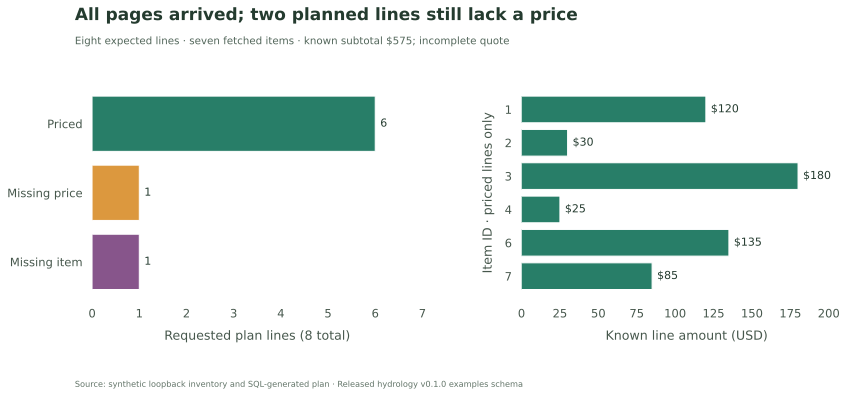

**Six of eight lines** contribute to the known **USD 575.00 subtotal**. ID 5 has an item but no price; ID 8 has no catalog row. Neither contributes a fabricated zero. ID 6 is priced despite its missing item name and contact: display completeness and pricing completeness are different. The two greeting overloads preserve the same two missing contacts and do not remove their plan lines.

3151

In [12]:
display(plan)
display(summary)
assert len(plan) == 8 and plan.item_id.nunique() == 8
assert int(plan.quantity.sum()) == 15
assert plan.price_status.value_counts().to_dict() == {"Priced": 6, "Missing price": 1, "Missing item": 1}
assert plan.loc[plan.item_id.isin([5, 8]), "known_line_usd"].isna().all()
assert plan.loc[plan.item_id.isin([6, 8]), "item_name"].isna().all()
assert plan.formal_label.isna().sum() == 2 and plan.casual_label.isna().sum() == 2
assert plan.loc[plan.category == "hardware", "formal_label"].eq("Good day, Ada.").all()
assert con.execute("SELECT count(*)=8 AND bool_and(squared=n*n) FROM generated").fetchone()[0]
assert con.execute("SELECT count(*)=7 AND count(DISTINCT id)=7 FROM catalog").fetchone()[0]
subtotal = float(plan.known_line_usd.sum())
assert subtotal == 575.0
fig, axes = plt.subplots(1, 2, figsize=(12, 5.8))
order = ["Priced", "Missing price", "Missing item"]
counts = summary.set_index("price_status").loc[order, "plan_lines"]
bars = axes[0].barh(order, counts, color=["#287E68", "#DC983E", "#87558B"])
axes[0].bar_label(bars, padding=5)
axes[0].set(xlim=(0, 7), xlabel="Requested plan lines (8 total)")
axes[0].invert_yaxis()
priced = plan.loc[plan.price_status == "Priced"]
bars = axes[1].barh(priced.item_id.astype(str), priced.known_line_usd.astype(float), color="#287E68")
axes[1].bar_label(bars, labels=[f"${float(x):.0f}" for x in priced.known_line_usd], padding=5)
axes[1].set(xlim=(0, 215), xlabel="Known line amount (USD)", ylabel="Item ID · priced lines only")
axes[1].invert_yaxis()
finish(
    fig,
    "All pages arrived; two planned lines still lack a price",
    f"Eight expected lines · seven fetched items · known subtotal ${subtotal:.0f}; incomplete quote",
    "Source: synthetic loopback inventory and SQL-generated plan · Released hydrology v0.1.0 examples schema",
    name=f"inventory-plan-{PAGE_SIZE}",
)
prose(
    f"**Six of eight lines** contribute to the known **USD {subtotal:.2f} subtotal**. "
    "ID 5 has an item but no price; ID 8 has no catalog row. Neither contributes a fabricated zero. "
    "ID 6 is priced despite its missing item name and contact: display completeness and pricing "
    "completeness are different. The two greeting overloads preserve the same two missing contacts "
    "and do not remove their plan lines."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/inventory-audit.json").write_text(
    json.dumps(
        {
            "page_size": PAGE_SIZE,
            "requests": fixture.requests,
            "plan": plan.to_dict("records"),
            "summary": summary.to_dict("records"),
            "known_subtotal_usd": subtotal,
        },
        indent=2,
        default=str,
    )
)

### Experiment: fetch one item per page

Change only `PAGE_SIZE` from **3 to 1**. Predict that successful local GET requests
increase from three to seven while all seven catalog rows, all eight plan rows,
nullable labels, the known subtotal and the chart stay unchanged. The request audit
is execution evidence; source completeness is established separately by the left join.

This fixture demonstrates the released pagination and secret-resolution contract,
not a live supplier integration, production retry policy or transaction. Real use
requires an endpoint implementing the expected `/items` JSON contract and a credential
provided intentionally for that endpoint. Do not reuse the fake token or point a
fixture notebook at a real account without reviewing its connection settings.

In [13]:
con.execute("DROP SECRET notebook_inventory")
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
fixture.close()
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-hydrology](https://github.com/Query-farm/vgi-hydrology)